## Variance-Gamma Flow Notebook
Train and evaluate a one-dimensional neural spline flow with a Variance-Gamma base distribution.


In [6]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = next(
    (path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (path / "levy_flow" / "flow.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing levy_flow/flow.py")
sys.path.insert(0, str(PROJECT_ROOT))

from levy_flow import NSFFlow, TrainConfig, VarianceGamma, train_flow, warm_start_base

torch.manual_seed(42)
np.random.seed(42)

Train size: 3520
Val size:   881
Test size:  1887
Training mean: 0.000154, standard deviation: 0.013141


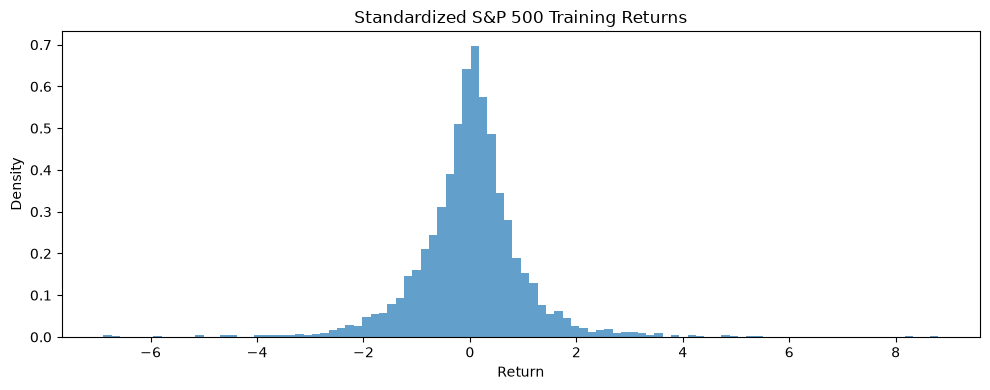

In [7]:
# Split chronologically, and fit scaling parameters on training data only.
returns = pd.read_csv(
    PROJECT_ROOT / "data" / "sp500_returns.csv",
    index_col=0,
    parse_dates=True,
)["^GSPC"].to_numpy(dtype=np.float64)

train_end = int(0.7 * len(returns))
train_end_inner = int(0.8 * train_end)
mean = returns[:train_end_inner].mean()
std = returns[:train_end_inner].std()
if not np.isfinite(std) or std == 0:
    raise ValueError("Training returns must have a finite, non-zero standard deviation")

train_data = ((returns[:train_end_inner] - mean) / std).astype(np.float32)
val_data = ((returns[train_end_inner:train_end] - mean) / std).astype(np.float32)
test_data = ((returns[train_end:] - mean) / std).astype(np.float32)

print(f"Train size: {len(train_data)}")
print(f"Val size:   {len(val_data)}")
print(f"Test size:  {len(test_data)}")
print(f"Training mean: {mean:.6f}, standard deviation: {std:.6f}")

plt.figure(figsize=(10, 4))
plt.hist(train_data, bins=100, density=True, alpha=0.7)
plt.title("Standardized S&P 500 Training Returns")
plt.xlabel("Return")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

Warm-start VG training NLL: 1.2971
epoch    1/300  train NLL =   1.6273   val NLL =   1.2697   lr = 1.00e-03
epoch   25/300  train NLL =   1.2950   val NLL =   0.9260   lr = 9.83e-04
epoch   50/300  train NLL =   1.2902   val NLL =   0.9249   lr = 9.34e-04
epoch   75/300  train NLL =   1.2891   val NLL =   0.9245   lr = 8.55e-04
epoch  100/300  train NLL =   1.2878   val NLL =   0.9372   lr = 7.52e-04
epoch  125/300  train NLL =   1.2880   val NLL =   0.9303   lr = 6.33e-04
epoch  150/300  train NLL =   1.2884   val NLL =   0.9281   lr = 5.05e-04
epoch  175/300  train NLL =   1.2873   val NLL =   0.9250   lr = 3.77e-04
epoch  200/300  train NLL =   1.2867   val NLL =   0.9302   lr = 2.57e-04
epoch  225/300  train NLL =   1.2878   val NLL =   0.9331   lr = 1.55e-04
epoch  250/300  train NLL =   1.2865   val NLL =   0.9280   lr = 7.63e-05
epoch  275/300  train NLL =   1.2860   val NLL =   0.9275   lr = 2.69e-05
epoch  300/300  train NLL =   1.2862   val NLL =   0.9299   lr = 1.00e-05

Re

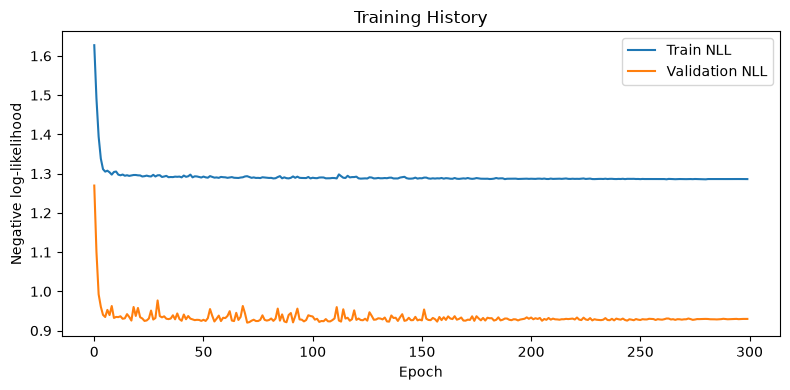

In [8]:
train_tensor = torch.from_numpy(train_data)
val_tensor = torch.from_numpy(val_data)

base = VarianceGamma(
    mu=0.0,
    theta=-0.2,
    sigma=1.0,
    nu=0.8,
    learnable=True,
)
base_nll = warm_start_base(base, train_tensor, epochs=200, lr=1e-3)
print(f"Warm-start VG training NLL: {base_nll:.4f}")

flow = NSFFlow(
    dim=1,
    base=base,
    num_layers=5,
    num_bins=8,
    tail_bound=10.0,
    hidden_dim=64,
    n_hidden=2,
)

history = train_flow(
    flow,
    train_tensor,
    cfg=TrainConfig(
        epochs=300,
        batch_size=256,
        lr=1e-3,
        grad_clip_norm=1.0,
        print_every=25,
        restore_best=True,
    ),
    x_val=val_tensor,
    device="cpu",
)

plt.figure(figsize=(8, 4))
plt.plot(history["train_nll"], label="Train NLL")
plt.plot(history["val_nll"], label="Validation NLL")
plt.xlabel("Epoch")
plt.ylabel("Negative log-likelihood")
plt.title("Training History")
plt.legend()
plt.tight_layout()
plt.show()

Test log-likelihood: -1.1818
Test NLL:            1.1818

Evaluation results (positive loss units):
test_nll                 : 1.1818
var_0.950_model          : 1.6016
var_0.950_empirical      : 1.3739
es_0.950_model           : 2.4101
es_0.950_empirical       : 2.2506
var_0.990_model          : 2.9278
var_0.990_empirical      : 2.5777
es_0.990_model           : 3.8419
es_0.990_empirical       : 3.8542
var_0.999_model          : 4.7701
var_0.999_empirical      : 5.9587
es_0.999_model           : 5.4381
es_0.999_empirical       : 8.1902


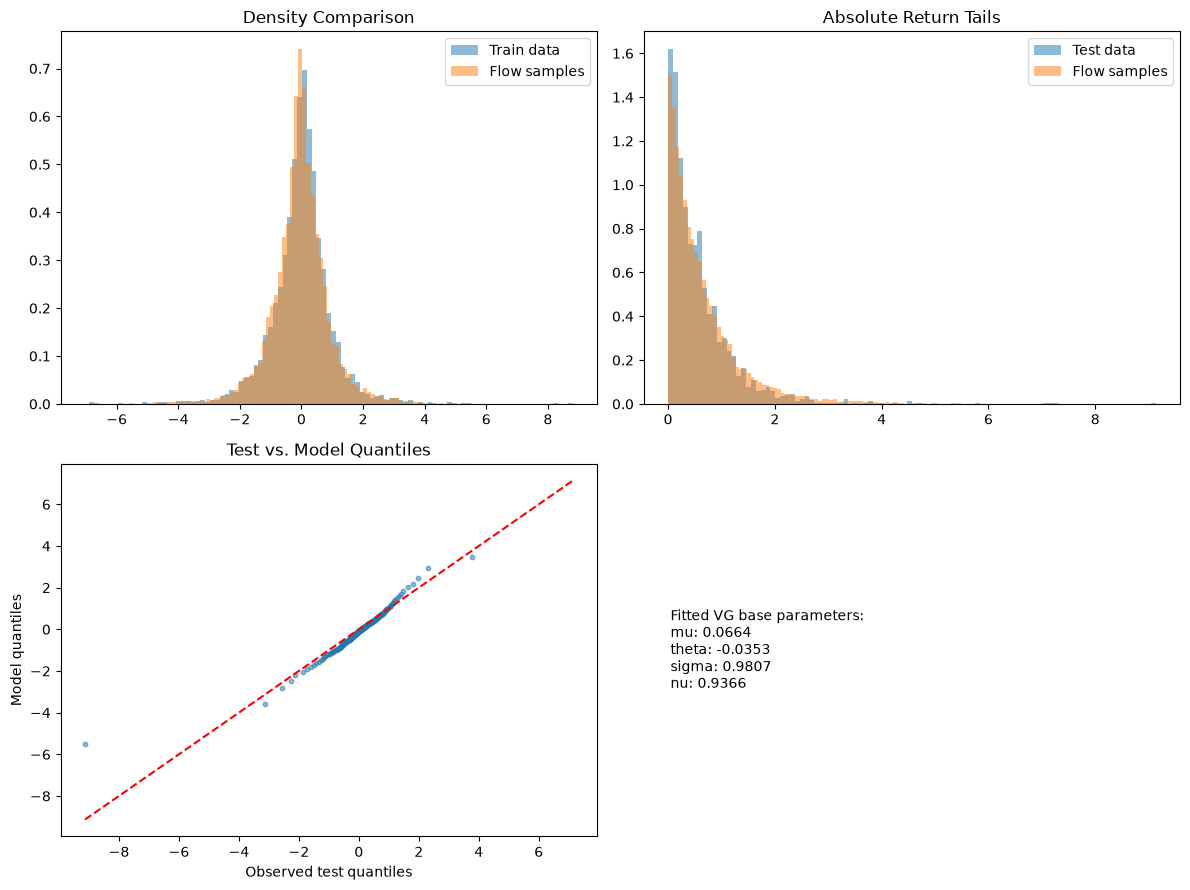

In [9]:
test_tensor = torch.from_numpy(test_data).unsqueeze(-1)
flow.eval()
with torch.no_grad():
    test_nll = -flow.log_prob(test_tensor).mean().item()

print(f"Test log-likelihood: {-test_nll:.4f}")
print(f"Test NLL:            {test_nll:.4f}")

levels = (0.95, 0.99, 0.999)
samples = flow.sample(20_000).squeeze(-1).cpu().numpy()
results = {"test_nll": test_nll}
for level in levels:
    model_cutoff = np.quantile(samples, 1 - level)
    empirical_cutoff = np.quantile(test_data, 1 - level)
    model_tail = samples[samples <= model_cutoff]
    empirical_tail = test_data[test_data <= empirical_cutoff]
    results[f"var_{level:.3f}_model"] = -model_cutoff
    results[f"var_{level:.3f}_empirical"] = -empirical_cutoff
    results[f"es_{level:.3f}_model"] = -model_tail.mean()
    results[f"es_{level:.3f}_empirical"] = -empirical_tail.mean()

print("\nEvaluation results (positive loss units):")
for key, value in results.items():
    print(f"{key:25s}: {value:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].hist(train_data, bins=100, density=True, alpha=0.5, label="Train data")
axes[0, 0].hist(samples, bins=100, density=True, alpha=0.5, label="Flow samples")
axes[0, 0].set_title("Density Comparison")
axes[0, 0].legend()

axes[0, 1].hist(np.abs(test_data), bins=100, density=True, alpha=0.5, label="Test data")
axes[0, 1].hist(np.abs(samples), bins=100, density=True, alpha=0.5, label="Flow samples")
axes[0, 1].set_title("Absolute Return Tails")
axes[0, 1].legend()

sorted_test = np.sort(test_data)
probabilities = (np.arange(len(sorted_test)) + 0.5) / len(sorted_test)
model_quantiles = np.quantile(np.sort(samples), probabilities)
axes[1, 0].scatter(sorted_test[::10], model_quantiles[::10], alpha=0.5, s=10)
limits = [min(sorted_test.min(), model_quantiles.min()), max(sorted_test.max(), model_quantiles.max())]
axes[1, 0].plot(limits, limits, "r--")
axes[1, 0].set_title("Test vs. Model Quantiles")
axes[1, 0].set_xlabel("Observed test quantiles")
axes[1, 0].set_ylabel("Model quantiles")

axes[1, 1].axis("off")
base_parameters = {
    name: getattr(flow.base, name).item()
    for name in ("mu", "theta", "sigma", "nu")
}
axes[1, 1].text(
    0.05,
    0.5,
    "Fitted VG base parameters:\n" + "\n".join(
        f"{name}: {value:.4f}" for name, value in base_parameters.items()
    ),
    fontsize=10,
    va="center",
)

plt.tight_layout()
plt.show()